# Refuerzo exploratorio: elegir la mejor ruta ante un evento (TensorFlow / Keras)

**Componente exploratorio de la tesis.** El motor principal es el algoritmo genético. Aquí se explora si un agente de aprendizaje por refuerzo aprende a **elegir la mejor ruta candidata** cuando aparece un evento de congestión o cierre cuya gravedad solo se conoce de forma aproximada (un reporte con ruido).

- **Grafo real:** `grafo.json`, exportado con `python manage.py export_graph_json` (aristas y tráfico por franja de Google Routes API).
- **Episodio:** bodega en la Ciudad de Guatemala, 8 paradas de un corredor, una franja (pico matutino, valle o pico vespertino) y un evento aleatorio sobre la ruta planificada: congestión (×1.5 a ×4) o cierre de un tramo. El reporte del evento trae ruido.
- **Acciones (K = 4 candidatas):** 0 = genético planificado con el tráfico de la franja (no ve el evento); 1 = genético replanificado con el evento **reportado**; 2 = convencional (proximidad sucesiva geográfica); 3 = genético por km.
- **Recompensa:** −(minutos + λ·km), con los minutos medidos con el evento **real**.
- **Agente:** red densa de Keras con política tipo DQN (ε-greedy y repetición de experiencias). Cada episodio es una sola decisión, así que es un *bandido contextual* (γ = 0).
- **Comparación:** contra «siempre el genético replanificado» y contra el **oráculo** (la mejor candidata con información perfecta). Los resultados se reportan aunque no superen al genético.
- Como en la app, la terracería se evita (penalización ×20).

En Colab: sube `grafo.json` y `genetic.py` (de `logistics/routing/`) a la sesión.

In [1]:
import heapq, json, math, random, sys, time, importlib.util
from pathlib import Path
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

SEMILLA = 2026
random.seed(SEMILLA); np.random.seed(SEMILLA); tf.random.set_seed(SEMILLA)
print('TensorFlow', tf.__version__)

# El MISMO algoritmo genético del sistema (solo biblioteca estándar)
gpath = next(p for p in [Path('genetic.py'), Path('../../logistics/routing/genetic.py')] if p.exists())
spec = importlib.util.spec_from_file_location('genetic', gpath)
genetic = importlib.util.module_from_spec(spec); sys.modules['genetic'] = genetic; spec.loader.exec_module(genetic)
G = json.loads(Path('grafo.json').read_text(encoding='utf-8'))
print('Fuente:', G['fuente_datos'], '|', len(G['nodos']), 'nodos,', len(G['aristas']), 'aristas')

TensorFlow 2.19.1
Fuente: {'edges': 'google', 'traffic': 'google_routes'} | 108 nodos, 258 aristas


## Grafo en memoria y Dijkstra (pesos ≥ 0; el tráfico multiplica por ≥ 1)

In [2]:
codes = [n['code'] for n in G['nodos']]
idx = {c: i for i, c in enumerate(codes)}
dept = [n['department'] for n in G['nodos']]
LAT = [n['lat'] for n in G['nodos']]; LON = [n['lon'] for n in G['nodos']]
E = G['aristas']
efrom = np.array([idx[e['from']] for e in E]); eto = np.array([idx[e['to']] for e in E])
t0 = np.array([e['t0_min'] for e in E]); km = np.array([e['km'] for e in E])
unpaved = np.array([e['road_class'] == 'unpaved' for e in E])
MULT = {k: np.array(v) for k, v in G['multiplicadores'].items()}
adj = [[] for _ in codes]
for e, (u, v) in enumerate(zip(efrom, eto)):
    adj[u].append((int(v), e))

def pesos(franja, extra=None, cerrado=(), criterio='time', penalizar=True):
    w = (t0 * MULT[f'{franja}|weekday']) if criterio == 'time' else km.copy()
    if penalizar:
        w = np.where(unpaved, w * 20.0, w)  # como la app: se evita la terracería (solo para ELEGIR el camino)
    if extra is not None:
        w = w * extra
    w = w.copy(); w[list(cerrado)] = np.inf
    return w

def dijkstra(w, s):
    dist = [math.inf] * len(codes); prev = [-1] * len(codes); dist[s] = 0.0; pq = [(0.0, s)]
    while pq:
        d, u = heapq.heappop(pq)
        if d > dist[u]:
            continue
        for v, e in adj[u]:
            nd = d + w[e]
            if nd < dist[v]:
                dist[v], prev[v] = nd, e; heapq.heappush(pq, (nd, v))
    return dist, prev

def camino(prev, s, t):
    out = []
    while t != s and prev[t] != -1:
        out.append(prev[t]); t = int(efrom[prev[t]])
    return out[::-1]

def matriz(w, nodos):
    filas = []
    for a in nodos:
        dist, _ = dijkstra(w, a)
        filas.append([float(dist[b]) for b in nodos])
    return filas

def medir(orden, nodos, w_plan, w_real, w_min):
    """Recorre el orden por los caminos elegidos con w_plan; minutos con el tráfico REAL.
    Si el camino pasa por un tramo cerrado, el mensajero se desvía (camino con w_real)."""
    minutos = distancia = 0.0; seq = [0, *orden, 0]
    for a, b in zip(seq, seq[1:]):
        p = camino(dijkstra(w_plan, nodos[a])[1], nodos[a], nodos[b])
        if any(not np.isfinite(w_real[e]) for e in p):
            p = camino(dijkstra(w_real, nodos[a])[1], nodos[a], nodos[b])
        minutos += float(sum(w_min[e] for e in p)); distancia += float(sum(km[e] for e in p))
    return minutos, distancia
print('Dijkstra listo')

Dijkstra listo


## Episodios y candidatas

In [3]:
DEPOSITO = idx['ciudad-guatemala']
CORREDORES = {'occidente': ('SA', 'CM', 'SO', 'TO', 'QZ'), 'sur': ('ES', 'SU', 'RE', 'SR'),
              'atlantico': ('PR', 'ZA', 'IZ', 'CQ')}
FRANJAS = ['peak_am', 'mid_morning', 'peak_pm']
LAMBDA = 0.5  # minutos por km en la recompensa
GA = genetic.GeneticParams(population=40, generations=150, stall_generations=25)

def proximidad_sucesiva(nodos):
    pend, orden, cur = set(range(1, len(nodos))), [], nodos[0]
    def d(a, b):
        return math.hypot(LAT[a] - LAT[b], (LON[a] - LON[b]) * math.cos(math.radians(14.6)))
    while pend:
        j = min(pend, key=lambda j: (d(cur, nodos[j]), j)); orden.append(j); pend.remove(j); cur = nodos[j]
    return orden

def episodio(rng):
    corredor = rng.choice(list(CORREDORES))
    pool = [i for i, d in enumerate(dept) if d in CORREDORES[corredor] and i != DEPOSITO]
    nodos = [DEPOSITO, *rng.sample(pool, 8)]
    franja = rng.choice(FRANJAS)
    w0 = pesos(franja)
    plan0 = genetic.solve(matriz(w0, nodos), GA, True).order
    usadas, seq = [], [0, *plan0, 0]
    for a, b in zip(seq, seq[1:]):
        usadas += camino(dijkstra(w0, nodos[a])[1], nodos[a], nodos[b])
    usadas = [e for e in dict.fromkeys(usadas)]
    tramo = rng.sample(usadas, min(4, len(usadas)))
    cierre = rng.random() < 0.25
    severidad = 1.0 if cierre else rng.uniform(1.5, 4.0)
    extra_real = np.ones(len(E)); cerr = tuple(tramo[:1]) if cierre else ()
    if not cierre:
        extra_real[tramo] = severidad
    reporte = 1.0 if cierre else max(1.0, severidad * rng.uniform(0.6, 1.4))  # reporte con ruido
    extra_rep = np.ones(len(E))
    if not cierre:
        extra_rep[tramo] = reporte
    w_real = pesos(franja, extra_real, cerr)
    w_rep = pesos(franja, extra_rep, cerr)
    min_real = pesos(franja, extra_real, cerr, penalizar=False)  # minutos reales, sin penalización
    min_rep = pesos(franja, extra_rep, cerr, penalizar=False)
    wkm = pesos(franja, criterio='distance', cerrado=cerr)
    plan1 = genetic.solve(matriz(w_rep, nodos), GA, True).order
    plan2 = proximidad_sucesiva(nodos)
    plan3 = genetic.solve(matriz(wkm, nodos), GA, True).order
    cands = [(plan0, w0), (plan1, w_rep), (plan2, wkm), (plan3, wkm)]
    medidas = [medir(o, nodos, wp, w_real, min_real) for o, wp in cands]
    estimadas = [medir(o, nodos, wp, w_rep, min_rep) for o, wp in cands]  # lo que se puede estimar con el reporte
    recompensas = [-(m + LAMBDA * k) for m, k in medidas]
    escala = max(abs(r) for r in recompensas)
    obs = np.array([*(1.0 if franja == f else 0.0 for f in FRANJAS), 1.0 if cierre else 0.0, (reporte - 1) / 3,
                    *[-(m + LAMBDA * k) / escala for m, k in estimadas]], dtype=np.float32)
    return obs, np.array(recompensas, dtype=np.float32) / escala, medidas

rng = random.Random(SEMILLA)
inicio = time.time()
datos = [episodio(rng) for _ in range(1500)]
print(f'{len(datos)} episodios en {time.time() - inicio:.0f} s')
entreno, prueba = datos[:1200], datos[1200:]

1500 episodios en 91 s


## Agente DQN (Keras) con repetición de experiencias

In [4]:
K = 4
red = tf.keras.Sequential([tf.keras.layers.Input((len(entreno[0][0]),)),
                           tf.keras.layers.Dense(64, activation='relu'),
                           tf.keras.layers.Dense(64, activation='relu'),
                           tf.keras.layers.Dense(K)])
red.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss='mse')
memoria, curva = [], []
eps, rng_a = 1.0, np.random.default_rng(SEMILLA)
for epoca in range(6):
    for obs, r, _ in entreno:
        a = int(rng_a.integers(K)) if rng_a.random() < eps else int(np.argmax(red(obs[None], training=False)[0]))
        memoria.append((obs, a, r[a]))
        eps = max(0.05, eps * 0.998)
        if len(memoria) >= 64 and len(memoria) % 16 == 0:
            lote = [memoria[i] for i in rng_a.integers(len(memoria), size=64)]
            X = np.stack([o for o, _, _ in lote]); q = red(X, training=False).numpy()
            for i, (_, a_i, r_i) in enumerate(lote):
                q[i, a_i] = r_i  # γ = 0: una decisión por episodio
            red.train_on_batch(X, q)
    elegidas = np.argmax(red(np.stack([o for o, _, _ in prueba]), training=False).numpy(), axis=1)
    curva.append(float(np.mean([r[a] for (_, r, _), a in zip(prueba, elegidas)])))
    print(f'época {epoca + 1}: recompensa media en prueba {curva[-1]:.4f} (ε = {eps:.2f})')

época 1: recompensa media en prueba -0.8815 (ε = 0.09)


época 2: recompensa media en prueba -0.8749 (ε = 0.05)


época 3: recompensa media en prueba -0.8764 (ε = 0.05)


época 4: recompensa media en prueba -0.8755 (ε = 0.05)


época 5: recompensa media en prueba -0.8777 (ε = 0.05)


época 6: recompensa media en prueba -0.8779 (ε = 0.05)


## Resultados en episodios de prueba (no vistos)

,política,minutos_media,km_media,elige_la_mejor_%
0,Agente DQN (Keras),1168.6,690.1,53.0
1,Siempre genético replanificado (1),1157.6,693.6,84.0
2,Siempre genético sin el evento (0),1290.3,704.4,9.0
3,Siempre convencional (2),1331.5,740.2,1.7
4,Oráculo (información perfecta),1154.2,688.6,100.0


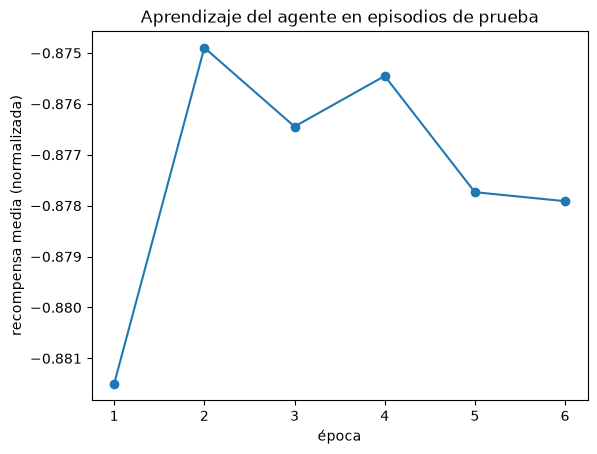

In [5]:
acciones_dqn = np.argmax(red(np.stack([o for o, _, _ in prueba]), training=False).numpy(), axis=1)

def resumen(nombre, acciones):
    mins = [m[a][0] for (_, _, m), a in zip(prueba, acciones)]
    kms = [m[a][1] for (_, _, m), a in zip(prueba, acciones)]
    mejor = [int(np.argmax(r)) for _, r, _ in prueba]
    return {'política': nombre, 'minutos_media': round(float(np.mean(mins)), 1), 'km_media': round(float(np.mean(kms)), 1),
            'elige_la_mejor_%': round(100 * float(np.mean([a == b for a, b in zip(acciones, mejor)])), 1)}

n = len(prueba)
tabla = pd.DataFrame([
    resumen('Agente DQN (Keras)', acciones_dqn),
    resumen('Siempre genético replanificado (1)', [1] * n),
    resumen('Siempre genético sin el evento (0)', [0] * n),
    resumen('Siempre convencional (2)', [2] * n),
    resumen('Oráculo (información perfecta)', [int(np.argmax(r)) for _, r, _ in prueba]),
])
display(tabla)
plt.plot(range(1, len(curva) + 1), curva, marker='o'); plt.xlabel('época'); plt.ylabel('recompensa media (normalizada)')
plt.title('Aprendizaje del agente en episodios de prueba'); plt.show()

## Lectura

- Si el agente **no supera** a «siempre genético replanificado», la conclusión es que, con esta información, el genético con el evento reportado ya es una política fuerte y el refuerzo no aporta; se reporta tal cual.
- La distancia al **oráculo** mide cuánto valor queda en mejorar la información del evento (reportes más precisos), no en el algoritmo.
- Limitaciones: episodios de una sola decisión, 8 paradas, tráfico por franja (no en vivo) y eventos simulados sobre el grafo real.